In [74]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit
from scipy.stats import chi2, lognorm

# successful fits: 
# LV4 + aSyn WT                 
# LV4 + aSyn E61V
# LV4 + aSyn A124T
# LV4 + aSyn E46K
# POPG + aSyn WT
# POPG + 25uM aSyn variants
# DOPC/GM1 + aSyn WT
# DOPC/GM1 + 25uM aSyn variants
# DOPC/DOPS + aSyn WT
# DOPC/DOPS + 25uM aSyn variants

# Observables:
# 1. Median radius
# 2. Fraction of P(r) shifted to higher values (integral)
# 3. Total EDP integral
# 4. EDP asymmetry

color_dict = {
    "WT": "dodgerblue",
    "A124T": "crimson",
    "E46K": "darkorange",
    "E61V": "green",
}
fig_height = 4.5
target_folder = Path("/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/Results_and_Figures/Setup_and_aSyn_sketch_and_FINAL_comparison")

In [75]:
# collect samples in sorted way
# "LV4":       "#5967A8",  # slate blue
# "POPG":      "#C06C84",  # dusty rose
# "DOPC_GM1":  "#4C8C7A",  # sage teal
# "PCPS":      "#A68A64",  # warm taupe
LV4 = {
    "name": "LV4",
    "pure": "BII_S9",
    "color": "#5967A8",
    "WT": [
        "BIV_S1",
        # "BIV_S2",
        # "BIV_S3",
        "BIV_S4",
        "BIV_S5",
        "BIV_S6",
        "BIV_S7",
        "BIV_S8",
        "BIV_S9",
        "BIV_S10"],
    "A124T": [
        "BIV_S21",
        "BIV_S22",
        "BIV_S23",
        "BIV_S24",
        "BIV_S25",
        "BIV_S26",
        "BIV_S27",
        "BIV_S28",
        "BIV_S29",
        "BIV_S30",],
    "E61V": [
        "BIV_S11",
        "BIV_S12",
        "BIV_S13",
        "BIV_S14",
        "BIV_S15",
        "BIV_S16",
        "BIV_S17",
        "BIV_S18",
        "BIV_S19",
        "BIV_S20",],
    "E46K": [
        "BIV_S31",
        "BIV_S32",
        "BIV_S33",
        "BIV_S34",
        "BIV_S35",
        "BIV_S36",
        "BIV_S37",
        "BIV_S38",
        "BIV_S39",
        "BIV_S40",],
}
LV4_for_comparison = {
    "name": "LV4",
    "pure": "BII_S9",
    "WT_comparison": [
        "BIV_S7"],
    "A124T": [
        "BIV_S27"],
    "E61V": [
        "BIV_S17"],
    "E46K": [
        "BIV_S37",],
}
DOPC_GM1 = {
    "name": "DOPC/GM1 (8/2)",
    "pure": "BIX_S2",
    "color": "#4C8C7A",
    "WT": ["BVI_S1",
           "BVI_S2",
           "BVI_S3",
           "BVI_S4",
           "BVI_S5",
           "BVI_S6",
           "BVI_S7"],
    "WT_comparison": ["BVI_S4"],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}
POPG = {
    "name": "POPG",
    "pure": "BIX_S1",
    "color": "#C06C84",
    "WT": ["BVI_S11",
           "BVI_S12",
        #    "BVI_S13", BAD BACKGROUND SUBTRACTION
           "BVI_S14",
           "BVI_S15",
           "BVI_S16",
           "BVI_S17"],
    "WT_comparison": ["BVI_S14"],
    "A124T": ["BVI_S19"],
    "E61V": ["BVI_S18"],
    "E46K": ["BVI_S20"],
}
PCPS = {
    "name": "DOPC/DOPS (8/2)",
    "pure": "BII_S11",
    "color": "#A68A64",
    "WT": [
        "BIX_S15", #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
        "BIX_S16", #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
        "BIX_S17", #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
        "BIX_S18", #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
        "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",
        # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
        "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
        ],
    "WT_comparison": ["BVII_S5"],
    "A124T": ["BVII_S15"],
    "E61V": ["BVII_S10"],
    "E46K": ["BVII_S20"],
}

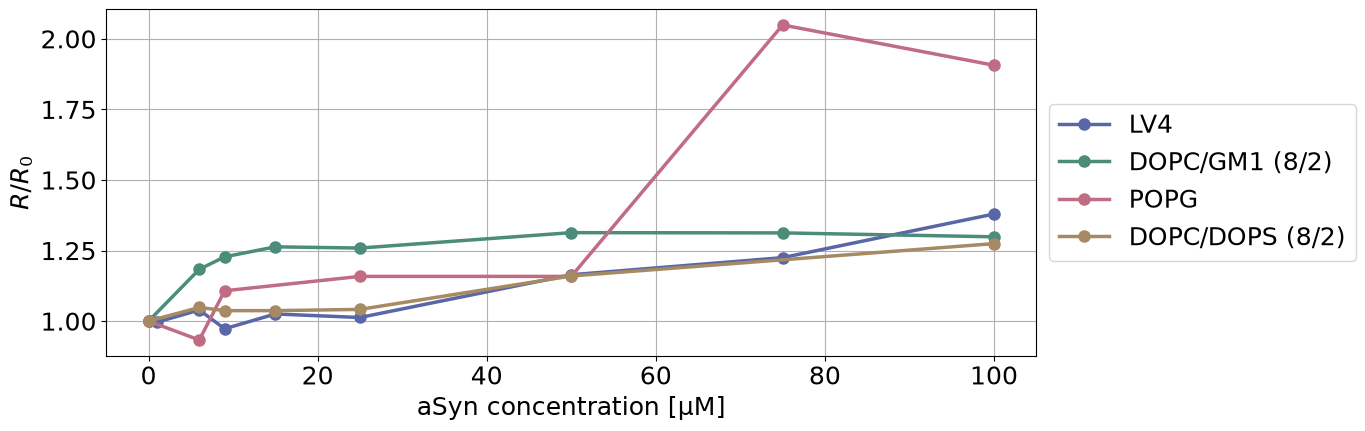

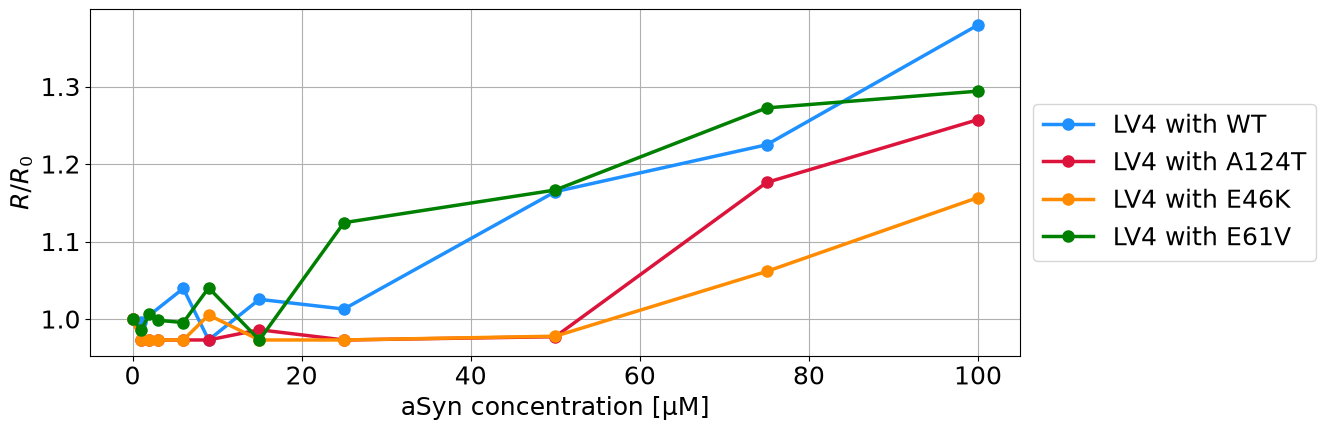

In [76]:
# aSyn-R/R0 plot 
# R0 is the median of the lognormal size distribution
succesful_series = [LV4, DOPC_GM1, POPG, PCPS]
f = plt.figure(figsize=(12, fig_height))
for series in succesful_series:
    aSyn_conc = [0]
    R_over_R0 = [1]
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0 = BM29.best_fits[series["pure"]][fit_function_name][1][0]
    for sample in series["WT"]:
        # print(sample)
        R = BM29.best_fits[sample][fit_function_name][1][0]
        aSyn_conc.append(BM29.concentrations[sample])
        R_over_R0.append(R/R0)
    color = series["color"]
    plt.plot(aSyn_conc, R_over_R0, label=series["name"], lw=2.5, marker='o', markersize=8, color=color)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$R/R_0$")
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
plt.show()
f.savefig(target_folder / "aSynWT_R_over_R0_plot.png", dpi=300, bbox_inches='tight')

# LV4 + variants, aSyn-R/R0 plot
variants = ["WT", "A124T", "E46K", "E61V"]
f = plt.figure(figsize=(12, fig_height))
for variant in variants:
    aSyn_conc = [0]
    R_over_R0 = [1]
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0 = BM29.best_fits[LV4["pure"]][fit_function_name][1][0]
    for sample in LV4[variant]:
        # print(sample)
        R = BM29.best_fits[sample][fit_function_name][1][0]
        aSyn_conc.append(BM29.concentrations[sample])
        R_over_R0.append(R/R0)
    color = color_dict[variant]
    plt.plot(aSyn_conc, R_over_R0, label=f"LV4 with {variant}", lw=2.5, marker='o', markersize=8, color=color)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$R/R_0$")
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
plt.show()
f.savefig(target_folder / "LV4_variants_R_over_R0_plot.png", dpi=300, bbox_inches='tight')

<>:21: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:43: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:21: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:43: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_39149/3955503433.py:21: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.ylabel("$\sigma/\sigma_0$")
/tmp/ipykernel_39149/3955503433.py:43: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw stri

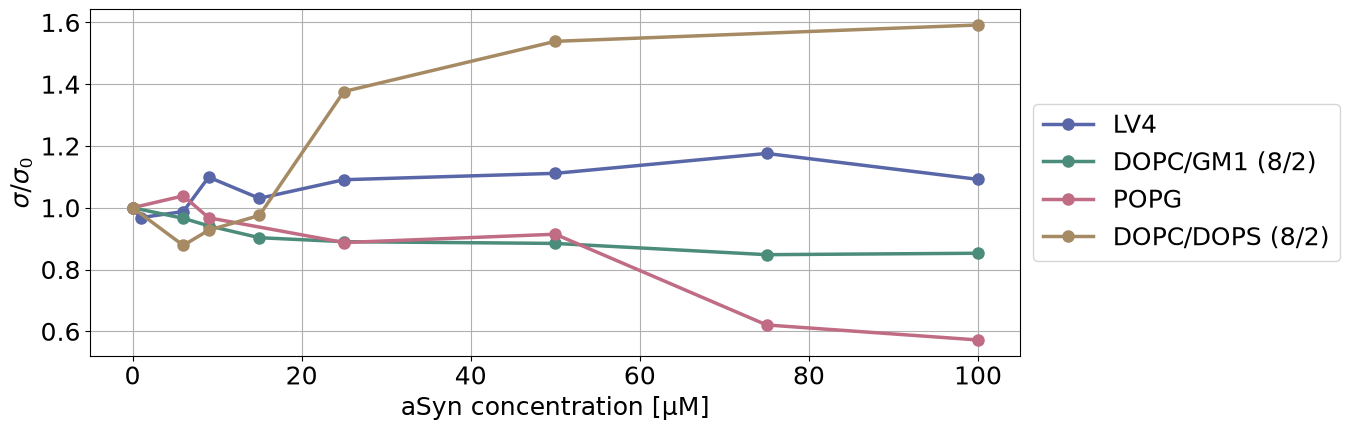

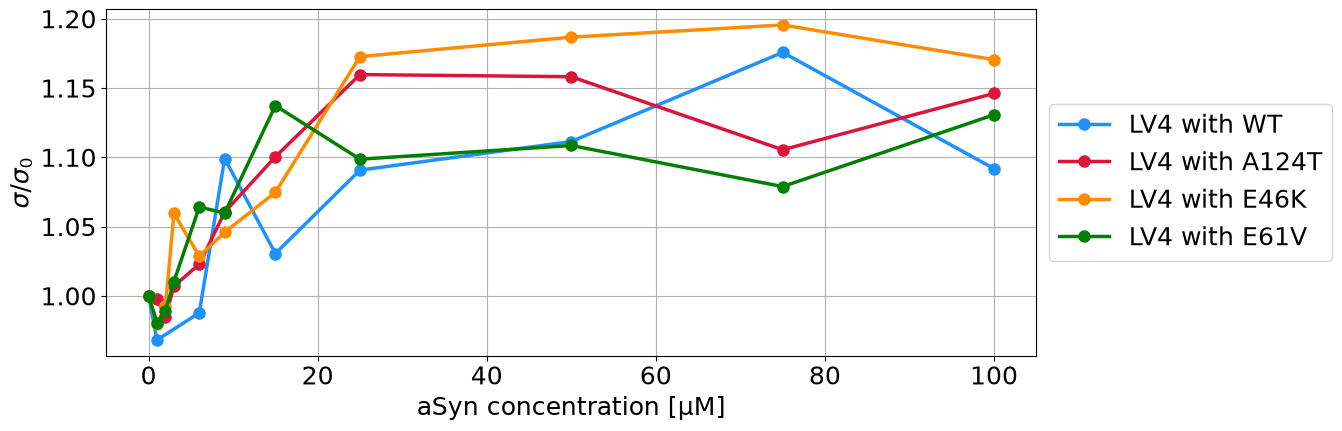

In [77]:
# aSyn-sigma/sigma0 plot 
# R0 is the median of the lognormal size distribution
succesful_series = [LV4, DOPC_GM1, POPG, PCPS]
f = plt.figure(figsize=(12, fig_height))
for series in succesful_series:
    aSyn_conc = [0]
    sigma_over_sigma0 = [1]
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    sigma0 = BM29.best_fits[series["pure"]][fit_function_name][1][1]
    for sample in series["WT"]:
        # print(sample)
        sigma = BM29.best_fits[sample][fit_function_name][1][1]
        aSyn_conc.append(BM29.concentrations[sample])
        sigma_over_sigma0.append(sigma/sigma0)
    color = series["color"]
    plt.plot(aSyn_conc, sigma_over_sigma0, label=series["name"], lw=2.5, marker='o', markersize=8, color=color)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$\sigma/\sigma_0$")
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
plt.show()
f.savefig(target_folder / "aSynWT_sigma_over_sigma0_plot.png", dpi=300, bbox_inches='tight')

# LV4 + variants, aSyn-R/R0 plot
variants = ["WT", "A124T", "E46K", "E61V"]
f = plt.figure(figsize=(12, fig_height))
for variant in variants:
    aSyn_conc = [0]
    sigma_over_sigma0 = [1]
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    sigma0 = BM29.best_fits[LV4["pure"]][fit_function_name][1][1]
    for sample in LV4[variant]:
        # print(sample)
        sigma = BM29.best_fits[sample][fit_function_name][1][1]
        aSyn_conc.append(BM29.concentrations[sample])
        sigma_over_sigma0.append(sigma/sigma0)
    color = color_dict[variant]
    plt.plot(aSyn_conc, sigma_over_sigma0, label=f"LV4 with {variant}", lw=2.5, marker='o', markersize=8, color=color)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$\sigma/\sigma_0$")
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
plt.show()
f.savefig(target_folder / "LV4_variants_sigma_over_sigma0_plot.png", dpi=300, bbox_inches='tight')

<>:23: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:47: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:23: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:47: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_39149/1664877757.py:23: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.ylabel("$EDP_{\mathrm{tot}}$")
/tmp/ipykernel_39149/1664877757.py:47: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw s

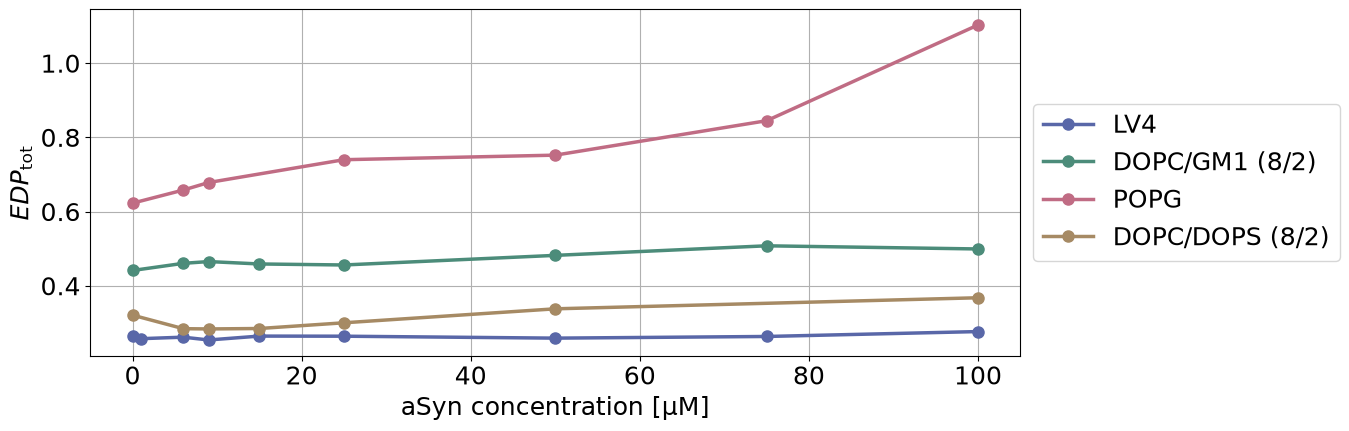

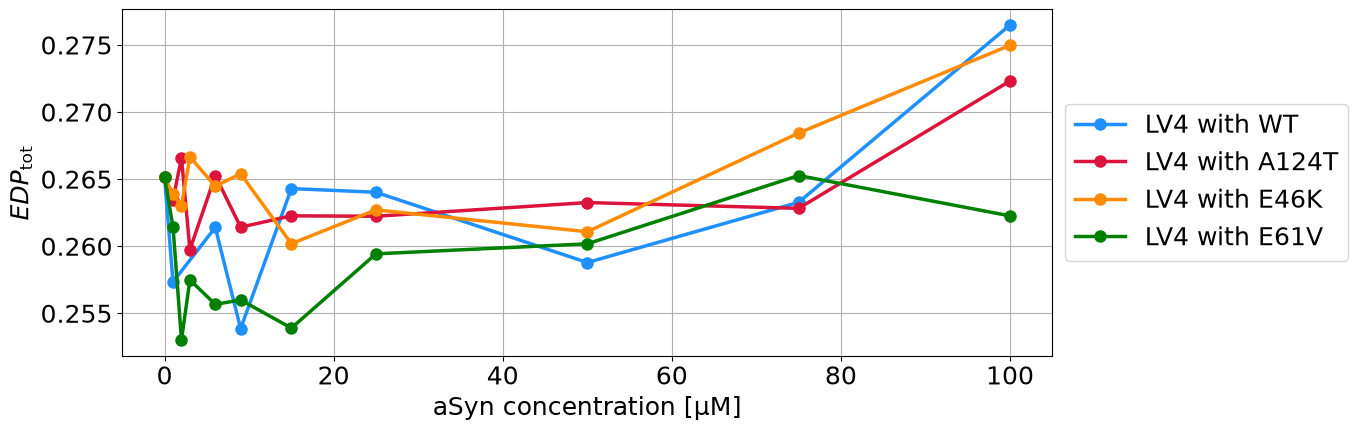

In [78]:
# aSyn - EDP_tot / EDP_tot_0 plot 
# R0 is the median of the lognormal size distribution
succesful_series = [LV4, DOPC_GM1, POPG, PCPS]
f = plt.figure(figsize=(12, fig_height))
for series in succesful_series:
    aSyn_conc = [0]
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[series["pure"]][fit_function_name][1][2:8]
    EDP_tot_0 = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=series["pure"])[0]
    rel_E_tot = [EDP_tot_0]
    for sample in series["WT"]:
        # print(sample)
        rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[sample][fit_function_name][1][2:8]
        EDP_tot = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=sample)[0]
        aSyn_conc.append(BM29.concentrations[sample])
        rel_E_tot.append(EDP_tot)
    color = series["color"]
    plt.plot(aSyn_conc, rel_E_tot, label=series["name"], lw=2.5, marker='o', markersize=8, color=color)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$EDP_{\mathrm{tot}}$")
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
plt.show()
f.savefig(target_folder / "aSynWT_EDP_tot_plot.png", dpi=300, bbox_inches='tight')

# LV4 + variants, aSyn-R/R0 plot
variants = ["WT", "A124T", "E46K", "E61V"]
f = plt.figure(figsize=(12, fig_height))
for variant in variants:
    aSyn_conc = [0]
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[LV4["pure"]][fit_function_name][1][2:8]
    EDP_tot_0 = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=LV4["pure"])[0]
    rel_E_tot = [EDP_tot_0]
    for sample in LV4[variant]:
        # print(sample)
        rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[sample][fit_function_name][1][2:8]
        EDP_tot = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=sample)[0]
        aSyn_conc.append(BM29.concentrations[sample])
        rel_E_tot.append(EDP_tot)
    color = color_dict[variant]
    plt.plot(aSyn_conc, rel_E_tot, label=f"LV4 with {variant}", lw=2.5, marker='o', markersize=8, color=color)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$EDP_{\mathrm{tot}}$")
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
plt.show()
f.savefig(target_folder / "LV4_variants_EDP_tot_plot.png", dpi=300, bbox_inches='tight')

<>:24: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:49: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:24: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:49: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_39149/1200501823.py:24: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.ylabel("$EDP_{\mathrm{asym}}$")
/tmp/ipykernel_39149/1200501823.py:49: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw 

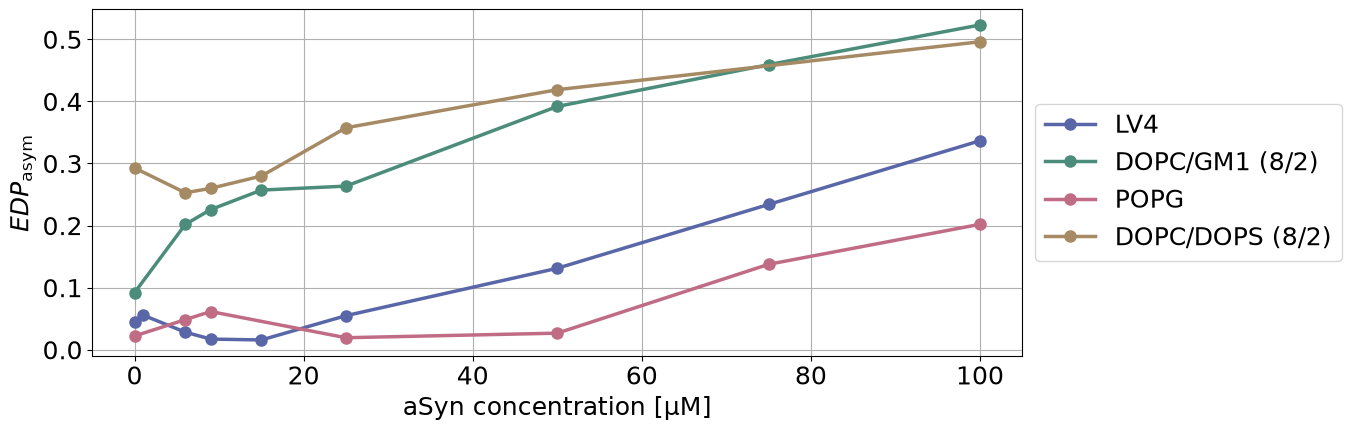

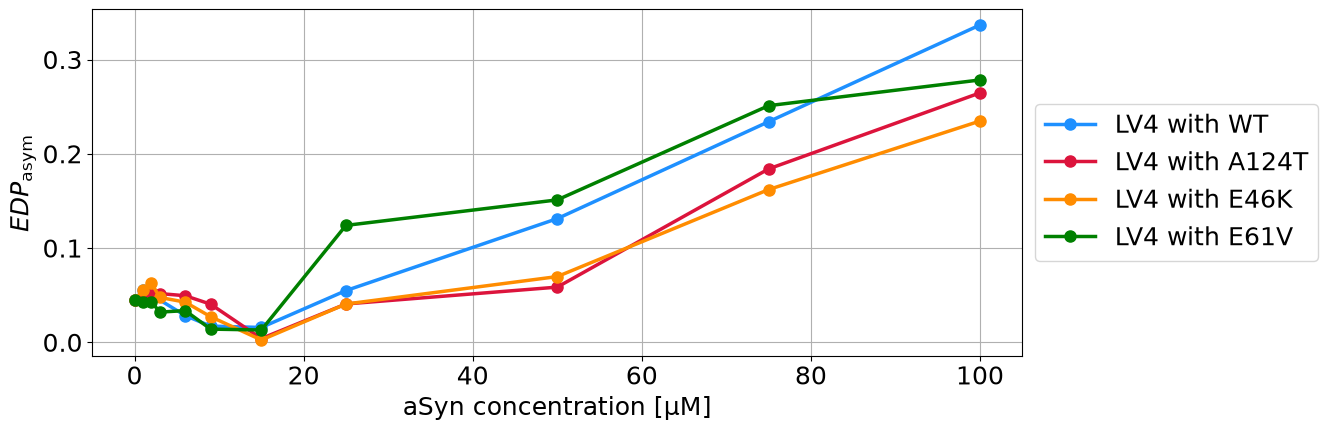

In [79]:
# aSyn - EDP_asym / EDP_asym_0 plot 
# R0 is the median of the lognormal size distribution
succesful_series = [LV4, DOPC_GM1, POPG, PCPS]
f = plt.figure(figsize=(12, fig_height))
for series in succesful_series:
    aSyn_conc = [0]
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[series["pure"]][fit_function_name][1][2:8]
    EDP_asym_0 = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=series["pure"])[3]
    rel_EDP_asym = [EDP_asym_0]

    for sample in series["WT"]:
        # print(sample)
        rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[sample][fit_function_name][1][2:8]
        EDP_asym = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=sample)[3]
        aSyn_conc.append(BM29.concentrations[sample])
        rel_EDP_asym.append(EDP_asym)
    color = series["color"]
    plt.plot(aSyn_conc, rel_EDP_asym, label=series["name"], lw=2.5, marker='o', markersize=8, color=color)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$EDP_{\mathrm{asym}}$")
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
plt.show()
f.savefig(target_folder / "aSynWT_EDP_asym_plot.png", dpi=300, bbox_inches='tight')

# LV4 + variants, aSyn-R/R0 plot
variants = ["WT", "A124T", "E46K", "E61V"]
f = plt.figure(figsize=(12, fig_height))
for variant in variants:
    aSyn_conc = [0]
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[LV4["pure"]][fit_function_name][1][2:8]
    EDP_asym_0 = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=LV4["pure"])[3]
    rel_EDP_asym = [EDP_asym_0]

    for sample in LV4[variant]:
        # print(sample)
        rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[sample][fit_function_name][1][2:8]
        EDP_asym = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=sample)[3]
        aSyn_conc.append(BM29.concentrations[sample])
        rel_EDP_asym.append(EDP_asym)
    color = color_dict[variant]
    plt.plot(aSyn_conc, rel_EDP_asym, label=f"LV4 with {variant}", lw=2.5, marker='o', markersize=8, color=color)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$EDP_{\mathrm{asym}}$")
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
plt.show()
f.savefig(target_folder / "LV4_variants_EDP_asym_plot.png", dpi=300, bbox_inches='tight')

In [80]:
# compute observables for VARIANT samples (for table in paper)
variants = ["pure", "WT_comparison", "A124T", "E46K", "E61V"]
lipid_types = [LV4_for_comparison, DOPC_GM1, POPG, PCPS]
for series in lipid_types:
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0 = BM29.best_fits[series["pure"]][fit_function_name][1][0]
    sigma0 = BM29.best_fits[series["pure"]][fit_function_name][1][1]
    # rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[series["pure"]][fit_function_name][1][2:8]
    # EDP_tot_0, _, _, EDP_asym_0, _ = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=series["pure"])

    for variant in variants:
        if variant == "pure":
            sample = series[variant]
        else:
            sample = series[variant][0]
        # print(sample)
        R = BM29.best_fits[sample][fit_function_name][1][0]
        sigma = BM29.best_fits[sample][fit_function_name][1][1]
        rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[sample][fit_function_name][1][2:8]
        EDP_tot, _, _, EDP_asym, _ = fit.EDP_analysis([rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h], fit_function_name=fit_function_name, sample=sample)
        R_over_R0 = R / R0
        sigma_over_sigma0 = sigma / sigma0
        print(f"{BM29.nice_sample_names[sample]} & {R_over_R0:.3g} & {sigma_over_sigma0:.3g} & {EDP_tot:.3g} & {EDP_asym:.3g} \\\\ ")

15 mM LVs & 1 & 1 & 0.265 & 0.0445 \\ 
15 mM LVs + 25 μM aSynWT & 1.01 & 1.09 & 0.264 & 0.0549 \\ 
15 mM LVs + 25 μM aSynA124T & 0.973 & 1.16 & 0.262 & 0.0407 \\ 
15 mM LVs + 25 μM aSynE46K & 0.973 & 1.17 & 0.263 & 0.0406 \\ 
15 mM LVs + 25 μM aSynE61V & 1.12 & 1.1 & 0.259 & 0.124 \\ 
15 mM DOPC/GM1 (8/2) & 1 & 1 & 0.441 & 0.092 \\ 
15 mM DOPC/GM1 (8/2) + 25 μM aSynWT & 1.26 & 0.89 & 0.456 & 0.264 \\ 
15 mM DOPC/GM1 (8/2) + 25 μM aSynA124T & 1.28 & 0.908 & 0.449 & 0.28 \\ 
15 mM DOPC/GM1 (8/2) + 25 μM aSynE46K & 1.26 & 0.906 & 0.467 & 0.309 \\ 
15 mM DOPC/GM1 (8/2) + 25 μM aSynE61V & 1.28 & 0.914 & 0.461 & 0.275 \\ 
15 mM POPG & 1 & 1 & 0.623 & 0.0222 \\ 
15 mM POPG + 25 μM aSynWT & 1.16 & 0.887 & 0.74 & 0.0194 \\ 
15 mM POPG + 25 μM aSynA124T & 1.11 & 0.935 & 0.727 & 0.0444 \\ 
15 mM POPG + 25 μM aSynE46K & 0.834 & 0.981 & 0.734 & 0.00289 \\ 
15 mM POPG + 25 μM aSynE61V & 1.18 & 0.867 & 0.755 & 0.0441 \\ 
15 mM DOPC/DOPS (8/2) & 1 & 1 & 0.321 & 0.293 \\ 
15 mM DOPC/DOPS (8/2) + 100 μM

BIV_S1
BIV_S4
BIV_S5
BIV_S6
BIV_S7
BIV_S8
BIV_S9
BIV_S10
BVI_S1
BVI_S2
BVI_S3
BVI_S4
BVI_S5
BVI_S6
BVI_S7
BVI_S11
BVI_S12
BVI_S14
BVI_S15
BVI_S16
BVI_S17
BIX_S15
BIX_S16
BIX_S17
BIX_S18
BIX_S19
BVII_S5


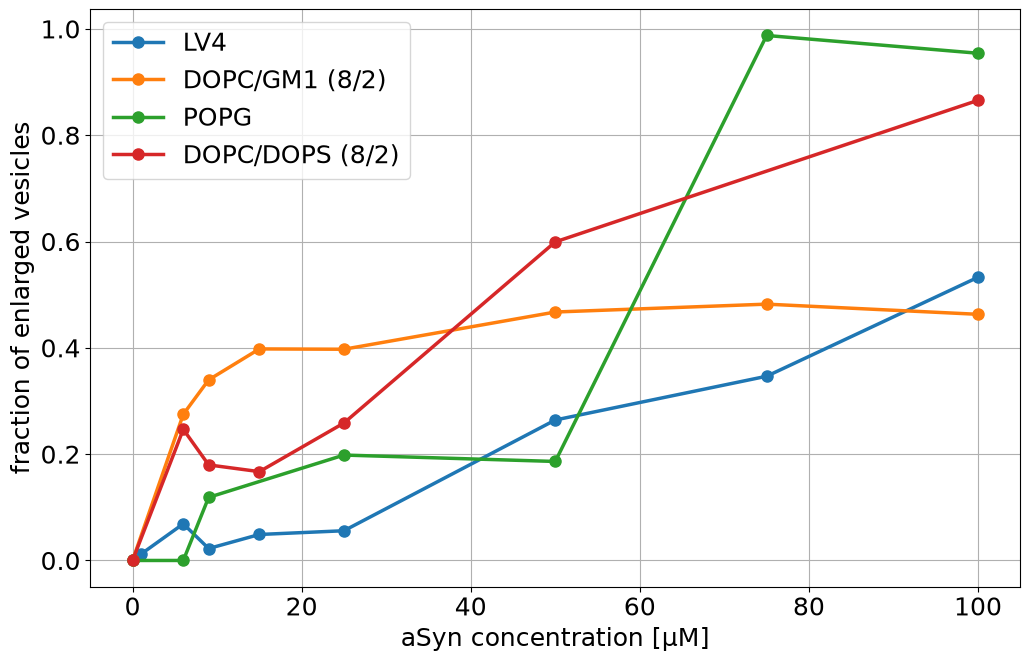

BIV_S1
BIV_S4
BIV_S5
BIV_S6
BIV_S7
BIV_S8
BIV_S9
BIV_S10
BIV_S21
BIV_S22
BIV_S23
BIV_S24
BIV_S25
BIV_S26
BIV_S27
BIV_S28
BIV_S29
BIV_S30
BIV_S31
BIV_S32
BIV_S33
BIV_S34
BIV_S35
BIV_S36
BIV_S37
BIV_S38
BIV_S39
BIV_S40
BIV_S11
BIV_S12
BIV_S13
BIV_S14
BIV_S15
BIV_S16
BIV_S17
BIV_S18
BIV_S19
BIV_S20


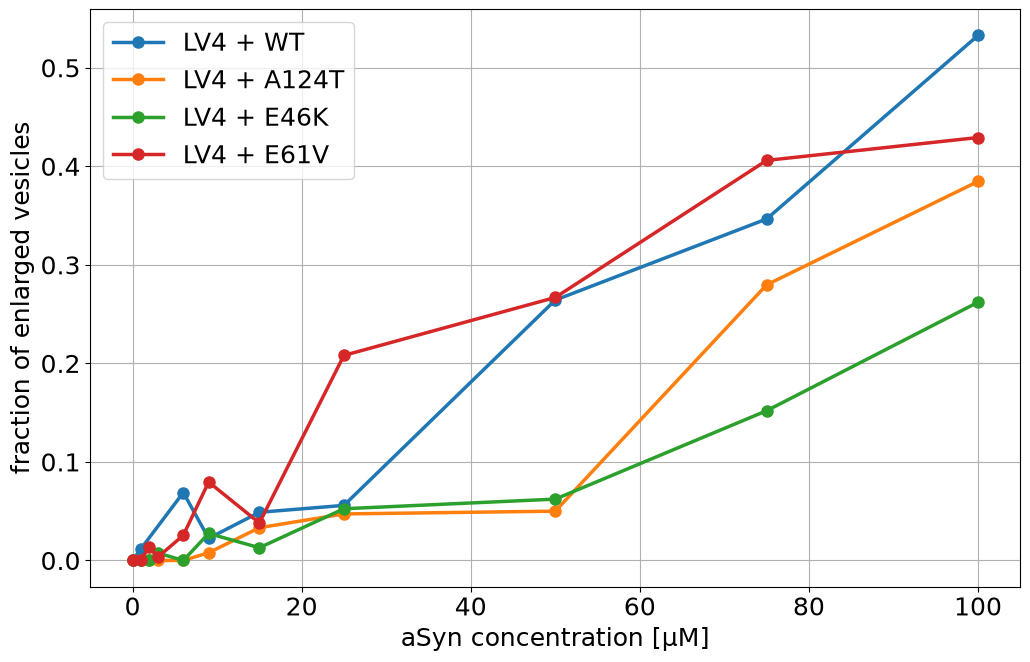

In [81]:
# aSyn - fraction of enlarged vesicles plot for WT (sph. asym. lognormal)
# R0 is the median of the lognormal size distribution
def lognorm_polydisp_enlargement(P_R0, P_R, R0, R, R_interval):
    intersection_index = []
    for i in range(len(P_R)):
        pos_cross_condition = (P_R0[i-1] > P_R[i-1]) and (P_R0[i] < P_R[i])
        radius_condition    = (np.abs(R_interval[i] - R0) < 12) 
        if pos_cross_condition and radius_condition:
            intersection_index.append(i)
    if len(intersection_index) == 0:
        print("WARNING: No intersections ...")
        integral_diff = 0
        return integral_diff
    elif len(intersection_index) != 1:
        print("WARNING: Multiple intersections ...")
    int_P_R = np.trapezoid(P_R[intersection_index[0]:], R_interval[intersection_index[0]:])
    int_P_R0 = np.trapezoid(P_R0[intersection_index[0]:], R_interval[intersection_index[0]:])
    integral_diff_larger = int_P_R - int_P_R0
    int_P_R = np.trapezoid(P_R[:intersection_index[0]], R_interval[:intersection_index[0]])
    int_P_R0 = np.trapezoid(P_R0[:intersection_index[0]], R_interval[:intersection_index[0]])
    integral_diff_smaller = int_P_R0 - int_P_R
    if integral_diff_larger < 0 or integral_diff_smaller < 0:
        print("WARNING: Unexpected curve trajectory ...")
    enlarged_fraction = integral_diff_smaller + integral_diff_larger
    return enlarged_fraction

succesful_series = [LV4, DOPC_GM1, POPG, PCPS]
f = plt.figure(figsize=(12, 7.5))
R_interval = np.linspace(0, R0 + 50, 1000)
for series in succesful_series:
    aSyn_conc = [0]
    frac_enlarged = [0]
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0, sigma0 = BM29.best_fits[series["pure"]][fit_function_name][1][0:2]
    P_R0 = lognorm.pdf(R_interval, s=sigma0, scale=R0)
    for sample in series["WT"]:
        print(sample)
        R, sigma = BM29.best_fits[sample][fit_function_name][1][0:2]
        aSyn_conc.append(BM29.concentrations[sample])
        P_R = lognorm.pdf(R_interval, s=sigma, scale=R)
        integral_diff = lognorm_polydisp_enlargement(P_R0, P_R, R0, R, R_interval)
        frac_enlarged.append(integral_diff)
    plt.plot(aSyn_conc, frac_enlarged, label=series["name"], lw=2.5, marker='o', markersize=8)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("fraction of enlarged vesicles")
plt.grid()
plt.legend()
plt.show()

# aSyn - fraction of enlarged vesicles plot for variants (sph. asym. lognormal)
variants = ["WT", "A124T", "E46K", "E61V"]
f = plt.figure(figsize=(12, 7.5))
R_interval = np.linspace(0, R0 + 50, 1000)
for variant in variants:
    aSyn_conc = [0]
    frac_enlarged = [0]
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0, sigma0 = BM29.best_fits[LV4["pure"]][fit_function_name][1][0:2]
    P_R0 = lognorm.pdf(R_interval, s=sigma0, scale=R0)
    for sample in LV4[variant]:
        print(sample)
        R, sigma = BM29.best_fits[sample][fit_function_name][1][0:2]
        aSyn_conc.append(BM29.concentrations[sample])
        P_R = lognorm.pdf(R_interval, s=sigma, scale=R)
        integral_diff = lognorm_polydisp_enlargement(P_R0, P_R, R0, R, R_interval)
        frac_enlarged.append(integral_diff)
    plt.plot(aSyn_conc, frac_enlarged, label=f"LV4 + {variant}", lw=2.5, marker='o', markersize=8)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("fraction of enlarged vesicles")
plt.grid()
plt.legend()
plt.show()

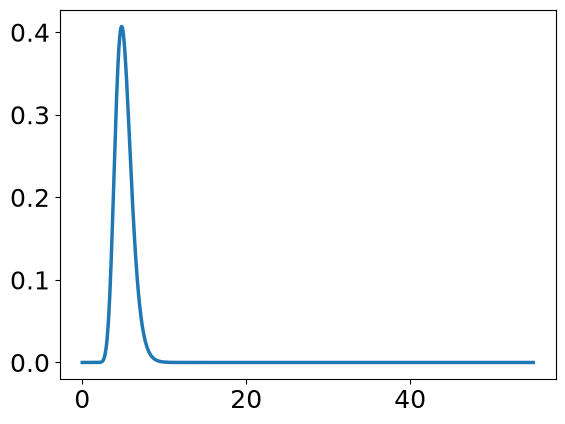

In [82]:
R0 = 5
sigma0  = 0.2
R_interval = np.linspace(0, R0 + 50, 1000)
P_R0 = lognorm.pdf(R_interval, s=sigma0, scale=R0)
plt.plot(R_interval, P_R0, lw=2.5)

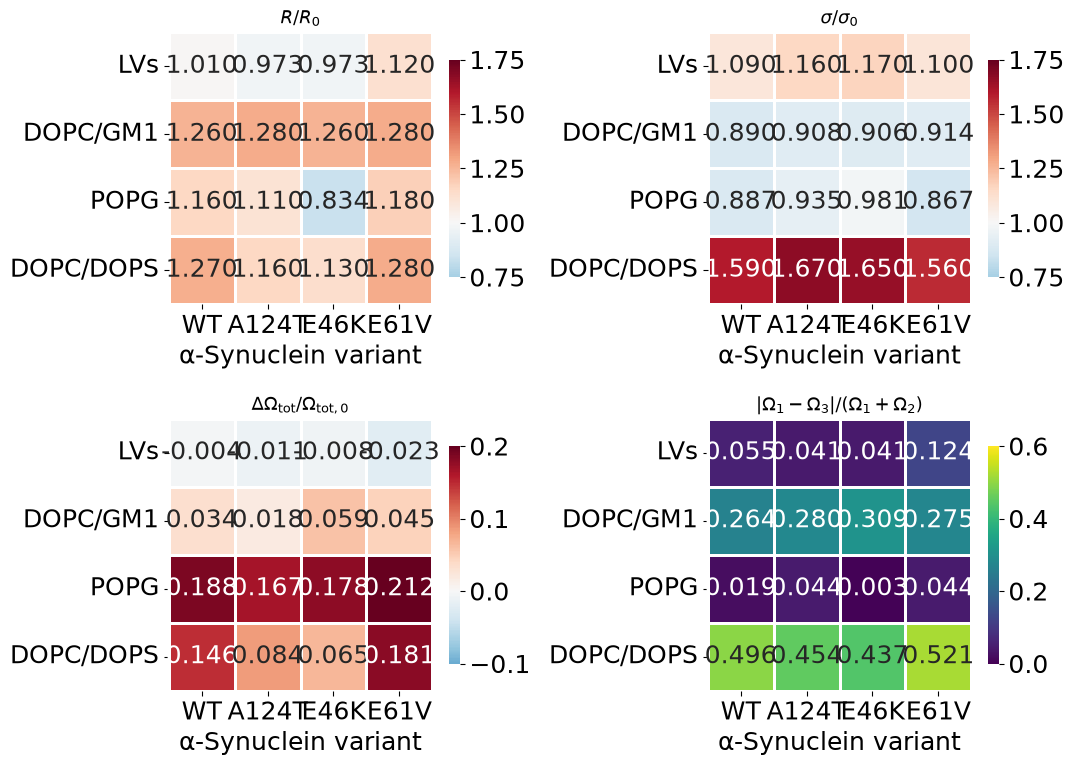

In [83]:
# heatmap for variants ==> BAD
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# Data
# --------------------------------------------------

data = [
    # Lipid, Variant, R/R0, sigma/sigma0, Omega_total, Asymmetry
    ("LVs", "Reference", 1.000, 1.000, 0.265, 0.0445),
    ("LVs", "WT",        1.010, 1.090, 0.264, 0.0549),
    ("LVs", "A124T",     0.973, 1.160, 0.262, 0.0407),
    ("LVs", "E46K",      0.973, 1.170, 0.263, 0.0406),
    ("LVs", "E61V",      1.120, 1.100, 0.259, 0.1240),

    ("DOPC/GM1", "Reference", 1.000, 1.000, 0.441, 0.0920),
    ("DOPC/GM1", "WT",        1.260, 0.890, 0.456, 0.2640),
    ("DOPC/GM1", "A124T",     1.280, 0.908, 0.449, 0.2800),
    ("DOPC/GM1", "E46K",      1.260, 0.906, 0.467, 0.3090),
    ("DOPC/GM1", "E61V",      1.280, 0.914, 0.461, 0.2750),

    ("POPG", "Reference", 1.000, 1.000, 0.623, 0.0222),
    ("POPG", "WT",        1.160, 0.887, 0.740, 0.0194),
    ("POPG", "A124T",     1.110, 0.935, 0.727, 0.0444),
    ("POPG", "E46K",      0.834, 0.981, 0.734, 0.00289),
    ("POPG", "E61V",      1.180, 0.867, 0.755, 0.0441),

    ("DOPC/DOPS", "Reference", 1.000, 1.000, 0.321, 0.293),
    ("DOPC/DOPS", "WT",        1.270, 1.590, 0.368, 0.496),
    ("DOPC/DOPS", "A124T",     1.160, 1.670, 0.348, 0.454),
    ("DOPC/DOPS", "E46K",      1.130, 1.650, 0.342, 0.437),
    ("DOPC/DOPS", "E61V",      1.280, 1.560, 0.379, 0.521),
]

df = pd.DataFrame(
    data,
    columns=["Lipid", "Variant", "R_ratio", "sigma_ratio",
             "Omega_total", "Asymmetry"]
)

lipids = ["LVs", "DOPC/GM1", "POPG", "DOPC/DOPS"]
variants = ["WT", "A124T", "E46K", "E61V"]

# --------------------------------------------------
# Calculate relative change in total Omega
# --------------------------------------------------

reference = (
    df[df["Variant"] == "Reference"]
    .set_index("Lipid")["Omega_total"]
)

df["Delta_Omega"] = df.apply(
    lambda row: (row["Omega_total"] - reference[row["Lipid"]])
                / reference[row["Lipid"]],
    axis=1
)

# --------------------------------------------------
# Plotting
# --------------------------------------------------

observables = [
    ("R_ratio", r"$R/R_0$", 1, 0.75, 1.75),
    ("sigma_ratio", r"$\sigma/\sigma_0$", 1, 0.75, 1.75),
    ("Delta_Omega", r"$\Delta\Omega_{\mathrm{tot}}/\Omega_{\mathrm{tot},0}$",
     0, -0.1, 0.2),
    ("Asymmetry", r"$|\Omega_1-\Omega_3|/(\Omega_1+\Omega_2)$",
     None, 0, 0.6),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (column, title, center, vmin, vmax) in zip(
    axes.flat, observables
):
    matrix = (
        df[df["Variant"].isin(variants)]
        .pivot(index="Lipid", columns="Variant", values=column)
        .reindex(index=lipids, columns=variants)
    )

    sns.heatmap(
        matrix,
        ax=ax,
        annot=True,
        fmt=".3f",
        cmap="RdBu_r" if center is not None else "viridis",
        center=center,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.8,
        linecolor="white",
        cbar_kws={"shrink": 0.8}
    )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("α-Synuclein variant")
    ax.set_ylabel("")

plt.tight_layout()
# plt.savefig("variant_comparison_heatmaps.pdf", bbox_inches="tight")
# plt.savefig("variant_comparison_heatmaps.png", dpi=300,
            # bbox_inches="tight")
plt.show()
